# Music Store Customer Support (LangGraph multi-agent)

This project is a customer-support assistant for a digital music store, built on the Chinook sample database. A customer first proves who they are (customer ID, email or phone). The system then loads their saved music preferences and passes the question to a supervisor agent. The supervisor sends it to a music-catalog agent, an invoice agent, or both, and writes one combined answer. At the end, the conversation is used to update the customer's saved preferences.

**Stack:** Python, LangChain, LangGraph (`langgraph-supervisor`), an OpenAI chat model, and an in-memory SQLite copy of Chinook.

**Flow:** `verify_info` (-> `human_input` if needed) -> `load_memory` -> `supervisor` (-> `music_catalog` / `invoice_info`) -> `create_memory` -> END

In [ ]:
# Run once, then restart the kernel if packages were installed
%pip install -q langchain langchain-openai langchain-community langgraph langgraph-supervisor sqlalchemy requests python-dotenv ipykernel

## 0. Setup
Secrets and settings live in a `.env` file next to the notebook, never in the code: `OPENAI_API_KEY` for the provider and `MODEL_NAME` for the model. `Settings` reads them, and `get_llm()` builds the chat model in one place, so every agent and node shares the same model. `Settings.TEMPERATURE` controls randomness (currently 1.0); lower it to 0 if your model allows, for more repeatable tool calling.

In [1]:
"""Central configuration + LLM factory.

  - Load secrets from .env instead of hardcoding them.
  - Build the LLM in ONE place so every agent/node shares the same model.
"""

import os
from dotenv import load_dotenv  
from langchain_openai import ChatOpenAI

load_dotenv()

class Settings:
    """Holds constants used across the project.

    Define class attributes such as
        CHINOOK_URL  - the raw .sql URL from the spec (page 3)
        MODEL_NAME   - read from the environment (os.getenv)
        TEMPERATURE  - use 0 for tool-calling agents.
    """
   
    CHINOOK_URL = "https://raw.githubusercontent.com/lerocha/chinook-database/master/ChinookDatabase/DataSources/Chinook_Sqlite.sql"
    MODEL_NAME = os.getenv("MODEL_NAME")
    TEMPERATURE = 1.0



def get_llm():
    """Return a configured chat model instance.
    
    1. Read the model name and temperature from Settings.
    2. Instantiate your provider's chat model with Settings.MODEL_NAME
         and Settings.TEMPERATURE.
    3. Return it.
    
    """
    if not Settings.MODEL_NAME:
        raise ValueError("MODEL_NAME is not set. Add it to your .env file.")
    llm = ChatOpenAI(model_name=Settings.MODEL_NAME, temperature=Settings.TEMPERATURE)
    return llm


## 1. Database
`ChinookDatabase` downloads the Chinook SQL script and runs it in an in-memory SQLite database, wrapped by SQLAlchemy and LangChain's `SQLDatabase`. `StaticPool` with `check_same_thread=False` makes every connection share the one in-memory database, which would otherwise vanish or be separate per connection. All queries pass user values as bound parameters (`:name`) instead of f-strings, so input like `x' OR '1'='1` cannot change the SQL (SQL injection).

In [2]:
import sqlite3
import requests
from sqlalchemy import create_engine, text
from sqlalchemy.pool import StaticPool
from langchain_community.utilities.sql_database import SQLDatabase

class ChinookDatabase:
    """Owns the in-memory Chinook SQLite database and exposes a LangChain SQLDatabase.

    """

    def __init__(self, url: str):
        """Store the SQL-script URL and build the engine once.

          - save url on self
          - self._engine = self._build_engine()
          - self.db = SQLDatabase(self._engine)
        """
        self.url = url
        self._engine = self._build_engine()
        self.db = SQLDatabase(self._engine)

    def _build_engine(self):
        """Download the script, load it into sqlite3 ':memory:', wrap in SQLAlchemy.

          1. requests.get(url).text  -> the SQL script
          2. sqlite3.connect(":memory:", check_same_thread=False)
          3. connection.executescript(script)
          4. create_engine("sqlite://", creator=lambda: connection,
                           poolclass=StaticPool, connect_args={"check_same_thread": False})
        """
        response = requests.get(self.url)
        response.encoding = "utf-8"
        script = response.text  
        connection = sqlite3.connect(":memory:", check_same_thread=False)
        connection.executescript(script)
        engine = create_engine("sqlite://", creator=lambda: connection,
                               poolclass=StaticPool, connect_args={"check_same_thread": False})
        return engine



    def run(self, query: str, parameters: dict | None = None, fetch: str = "all"):
        """Run a SQL query and return the result.

        delegate to self.db.run(...). Look at its signature: it accepts
        `parameters` for bound values (:name placeholders) and a `fetch` mode.
        Security: always pass user values through `parameters`, never via f-strings.
        (SQL injection: what happens if an artist is named  x' OR '1'='1 ?)
        """
        runSQL= self.db.run(query, parameters=parameters, fetch=fetch)
        return runSQL  

    def query(self, sql: str, parameters: dict | None = None) -> list[dict]:
        """Run a SQL query and return rows as a list of dicts (column name -> value).

        Unlike run(), which returns a string, this gives the tools structured rows.
        Values go through bound parameters (:name placeholders), never f-strings.
        """
        with self._engine.connect() as conn:
            result = conn.execute(text(sql), parameters or {})
            return [dict(row) for row in result.mappings()]

    def list_tables(self) -> list[str]:
        """Return table names - handy for exploring in the notebook.
        """
        tables = self.db.get_usable_table_names()
        return tables


# Quick check: build the database and list its tables
chinook = ChinookDatabase(Settings.CHINOOK_URL)
print(chinook.list_tables())
print(chinook.run("SELECT CustomerId, FirstName, LastName FROM Customer LIMIT 3"))

C:\Users\Ahmed Reda\AppData\Local\Temp\ipykernel_39052\2014514762.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities.sql_database import SQLDatabase


['Album', 'Artist', 'Customer', 'Employee', 'Genre', 'Invoice', 'InvoiceLine', 'MediaType', 'Playlist', 'PlaylistTrack', 'Track']
[(1, 'Luís', 'Gonçalves'), (2, 'Leonie', 'Köhler'), (3, 'François', 'Tremblay')]


## 2. State
The `State` is shared by every node in the graph:
- `messages`: the conversation. The `add_messages` reducer appends new messages instead of overwriting the list.
- `customer_id`: set by `verify_info`; short-term memory for the current thread.
- `loaded_memory`: the customer's saved preferences as text, set by `load_memory` and used by the music agent.
- `remaining_steps`: required by the prebuilt ReAct agents so they stop before hitting the recursion limit.
- `auth_attempts`: number of failed verifications; guards the `verify_info` <-> `human_input` loop.

In [5]:
from typing_extensions import TypedDict, Annotated
from langgraph.graph.message import AnyMessage, add_messages
from langgraph.managed.is_last_step import RemainingSteps
from typing import List

class State(TypedDict):
    """State shared by every node in the graph.

    declare these fields with type hints
        customer_id: str                                    # short-term memory: set by verify_info
        messages: Annotated[list[AnyMessage], add_messages] # conversation history
        loaded_memory: str                                  # long-term prefs set by load_memory
        remaining_steps: RemainingSteps                     # needed by prebuilt ReAct agents

    """
    customer_id :str
    messages: Annotated[List[AnyMessage], add_messages]
    loaded_memory: str
    remaining_steps: RemainingSteps
    auth_attempts: int  # failed verification attempts; guards the verify_info <-> human_input loop




## 3. Tools
Seven tools in two classes. `MusicCatalogTools`: albums by artist, tracks by artist (plus similar artists in the same genre), songs by genre, and check whether a song exists. `InvoiceTools`: invoices by date, invoice lines by unit price, and the support employee for an invoice. The model chooses tools from their name, description and argument types, so each description says when to use it, what to pass and what comes back. Searches use `LIKE` so partial names work, and results are capped with `LIMIT`. Every invoice query filters on `customer_id`, and the invoice agent is told to use only the verified ID, so one customer cannot read another's invoices.

In [4]:
"""Invoice tools """
from langchain_core.tools import StructuredTool

class InvoiceTools:
    """Groups the 3 invoice queries and exposes them as LangChain tools.

    Tables: Customer, Invoice, InvoiceLine, Employee.
    Relations: Customer 1-* Invoice 1-* InvoiceLine ; Customer.SupportRepId -> Employee.EmployeeId.

    Security: every query filters by the verified customer_id so one customer can
    never read another's invoices. The invoice agent's prompt supplies that ID.
    """

    def __init__(self, db):

        self.db = db

    def get_invoices_by_customer_sorted_by_date(self, customer_id: str) -> list[dict] | str:
        """All invoices for the customer, most recent first.

        SELECT from Invoice WHERE CustomerId = :customer_id ORDER BY InvoiceDate DESC.
        """
        rows = self.db.query("""
            SELECT InvoiceId, InvoiceDate, Total
            FROM Invoice
            WHERE CustomerId = :customer_id
            ORDER BY InvoiceDate DESC
        """, {"customer_id": customer_id})
        if not rows:
            return f"No invoices found for customer '{customer_id}'."
        return [{"InvoiceId": row["InvoiceId"], "InvoiceDate": row["InvoiceDate"], "Total": row["Total"]} for row in rows]

    def get_invoices_sorted_by_unit_price(self, customer_id: str) -> list[dict] | str:
        """The customer's invoice lines, highest unit price first.

        unit price lives on InvoiceLine, so JOIN Invoice and InvoiceLine,
        filter by customer, ORDER BY UnitPrice DESC.
        """
        rows = self.db.query("""
            SELECT i.InvoiceId, t.Name AS TrackName, il.UnitPrice, il.Quantity
            FROM Invoice i
            JOIN InvoiceLine il ON i.InvoiceId = il.InvoiceId
            JOIN Track t ON il.TrackId = t.TrackId
            WHERE i.CustomerId = :customer_id
            ORDER BY il.UnitPrice DESC
            LIMIT 10
        """, {"customer_id": customer_id})
        if not rows:
            return f"No invoice lines found for customer '{customer_id}'."
        return [
            {"InvoiceId": row["InvoiceId"], "TrackName": row["TrackName"],
             "UnitPrice": row["UnitPrice"], "Quantity": row["Quantity"]}
            for row in rows
        ]

    def get_employee_by_invoice_and_customer(self, invoice_id: str, customer_id: str) -> dict | str:
        """The support employee tied to a specific invoice of a specific customer.

        JOIN Invoice -> Customer -> Employee (via SupportRepId). Filter on BOTH
        invoice_id and customer_id. Returns a message when the invoice isn't theirs.
        """

        rows = self.db.query("""
            SELECT e.EmployeeId, e.FirstName, e.LastName, e.Title
            FROM Invoice i
            JOIN Customer c ON i.CustomerId = c.CustomerId
            JOIN Employee e ON c.SupportRepId = e.EmployeeId
            WHERE i.InvoiceId = :invoice_id AND c.CustomerId = :customer_id
        """, {"invoice_id": invoice_id, "customer_id": customer_id})
        if not rows:
            return f"No employee found for invoice '{invoice_id}' and customer '{customer_id}'."
        row = rows[0]
        return {"EmployeeId": row["EmployeeId"], "FirstName": row["FirstName"], "LastName": row["LastName"], "Title": row["Title"]}

    def as_tools(self) -> list:
        """Wrap the three methods as LangChain tools (same approach as MusicCatalogTools)."""
        return [    StructuredTool.from_function(
            func=self.get_invoices_by_customer_sorted_by_date,
            name="get_invoices_by_customer_sorted_by_date",
            description="Use when the customer asks about their purchase history, e.g. 'my latest purchase' "
                        "or 'what did I buy last'. Pass customer_id as a string. Returns all invoices, "
                        "most recent first, as dicts with InvoiceId, InvoiceDate, and Total, "
                        "or a message saying none were found.",
        ),
                StructuredTool.from_function(
            func=self.get_invoices_sorted_by_unit_price,
            name="get_invoices_sorted_by_unit_price",
            description="Use when the customer asks about their most expensive items or purchases by price, "
                        "e.g. 'what was my priciest song'. Pass customer_id as a string. Returns up to 10 "
                        "invoice lines, highest unit price first, as dicts with InvoiceId, TrackName, "
                        "UnitPrice, and Quantity, or a message saying none were found.",
        ),
                StructuredTool.from_function(
            func=self.get_employee_by_invoice_and_customer,
            name="get_employee_by_invoice_and_customer",
            description="Use when the customer asks who helped them or which support rep handled a specific "
                        "invoice. Pass invoice_id and customer_id as strings. Returns a dict with "
                        "EmployeeId, FirstName, LastName, and Title, or a message saying none was found "
                        "(including when the invoice does not belong to the customer).",
        ),
        ]  


"""Music catalog tools"""
from langchain_core.tools import StructuredTool

class MusicCatalogTools:
    """Groups the 4 catalog queries and exposes them as LangChain tools.

    Tables you will need: Artist, Album, Track, Genre.
    Relations: Artist 1-* Album 1-* Track ; Track *-1 Genre.

    GENERAL RULES FOR EVERY METHOD
      - Use bound parameters (:artist), never f-strings.
      - Use LIKE with % wildcards so "Rolling Stones" matches "The Rolling Stones".
      - Cap results (LIMIT) so you don't flood the LLM context.
      - Return something the LLM can read (a string or list of dicts), and a clear
        message when nothing matches.
    """

    def __init__(self, db):
        """store the shared ChinookDatabase on self.db."""

        self.db = db

    def get_albums_by_artist(self, artist: str):
        """Albums by a given artist.

        JOIN Album and Artist, filter Artist.Name LIKE :artist.
        """
        rows = self.db.query("""
            SELECT Album.Title
            FROM Album
            JOIN Artist ON Album.ArtistId = Artist.ArtistId
            WHERE Artist.Name LIKE :artist
            LIMIT 10
        """, {"artist": f"%{artist}%"})
        if not rows:
            return f"No albums found for artist '{artist}'. Do not invent any."
        return [{"Title": row["Title"]} for row in rows]

    def get_tracks_by_artist(self, artist: str):
        """Songs by a given artist, plus songs by similar artists.

        JOIN Track -> Album -> Artist. "Similar" artists are other artists who have
        tracks in the same genre(s) as the requested artist.
        """
        tracks = self.db.query("""
            SELECT Track.Name AS TrackName, Album.Title AS AlbumTitle
            FROM Track
            JOIN Album ON Track.AlbumId = Album.AlbumId
            JOIN Artist ON Album.ArtistId = Artist.ArtistId
            WHERE Artist.Name LIKE :artist
            LIMIT 10
        """, {"artist": f"%{artist}%"})
        if not tracks:
            return f"No songs found for artist '{artist}'. Do not invent any."

        similar = self.db.query("""
            SELECT DISTINCT Track.Name AS TrackName, Artist.Name AS ArtistName
            FROM Track
            JOIN Album ON Track.AlbumId = Album.AlbumId
            JOIN Artist ON Album.ArtistId = Artist.ArtistId
            WHERE Track.GenreId IN (
                SELECT t.GenreId
                FROM Track t
                JOIN Album a ON t.AlbumId = a.AlbumId
                JOIN Artist ar ON a.ArtistId = ar.ArtistId
                WHERE ar.Name LIKE :artist
            )
            AND Artist.Name NOT LIKE :artist
            LIMIT 10
        """, {"artist": f"%{artist}%"})
        return {
            "tracks_by_artist": [
                {"TrackName": t["TrackName"], "AlbumTitle": t["AlbumTitle"]} for t in tracks
            ],
            "tracks_by_similar_artists": [
                {"TrackName": t["TrackName"], "ArtistName": t["ArtistName"]} for t in similar
            ],
        }

    def get_songs_by_genre(self, genre: str):
        """Songs in a genre.

        JOIN Track and Genre, filter Genre.Name LIKE :genre.
        Return track name + artist name (needs Album and Artist joins too).
        """
        rows = self.db.query("""
            SELECT Track.Name AS TrackName, Artist.Name AS ArtistName
            FROM Track
            JOIN Album ON Track.AlbumId = Album.AlbumId
            JOIN Artist ON Album.ArtistId = Artist.ArtistId
            JOIN Genre ON Track.GenreId = Genre.GenreId
            WHERE Genre.Name LIKE :genre
            LIMIT 10
        """, {"genre": f"%{genre}%"})
        if not rows:
            return f"No songs found for genre '{genre}'. Do not invent any."
        return [{"TrackName": r["TrackName"], "ArtistName": r["ArtistName"]} for r in rows]

    def check_for_songs(self, song_title: str):
        """Does a song with this title exist?

        search Track.Name with LIKE; return matches with album + artist.
        """
        rows = self.db.query("""
            SELECT Track.Name AS TrackName, Album.Title AS AlbumTitle, Artist.Name AS ArtistName
            FROM Track
            JOIN Album ON Track.AlbumId = Album.AlbumId
            JOIN Artist ON Album.ArtistId = Artist.ArtistId
            WHERE Track.Name LIKE :song_title
            LIMIT 10
        """, {"song_title": f"%{song_title}%"})
        if not rows:
            return f"No song titled '{song_title}' exists in the catalog."
        return [
            {"TrackName": r["TrackName"], "AlbumTitle": r["AlbumTitle"], "ArtistName": r["ArtistName"]}
            for r in rows
        ]

    def as_tools(self) -> list:
        """Wrap the methods above as LangChain tools for the agent.

        The LLM chooses tools using only the name, description and argument types,
        so each description says WHEN to use the tool, WHAT to pass, and WHAT comes back.
        """
        return [
            StructuredTool.from_function(
                func=self.get_albums_by_artist,
                name="get_albums_by_artist",
                description=(
                    "Use when the customer asks what albums an artist or band has. "
                    "Input: the artist name (partial names work, e.g. 'Rolling Stones'). "
                    "Returns up to 10 album titles, or a message saying none were found."
                ),
            ),
            StructuredTool.from_function(
                func=self.get_tracks_by_artist,
                name="get_tracks_by_artist",
                description=(
                    "Use when the customer asks for songs by an artist, or wants songs "
                    "that match an artist they like. Input: the artist name. Returns up to "
                    "10 of the artist's tracks with album titles, plus up to 10 tracks "
                    "from similar artists (same genre), or a message saying none were found."
                ),
            ),
            StructuredTool.from_function(
                func=self.get_songs_by_genre,
                name="get_songs_by_genre",
                description=(
                    "Use when the customer asks for songs in a genre such as Rock, Jazz "
                    "or Metal. Input: the genre name. Returns up to 10 tracks with their "
                    "artist names, or a message saying none were found."
                ),
            ),
            StructuredTool.from_function(
                func=self.check_for_songs,
                name="check_for_songs",
                description=(
                    "Use when the customer asks whether a specific song is in the store. "
                    "Input: the song title (partial titles work). Returns matching tracks "
                    "with album and artist, or a message saying the song does not exist."
                ),
            ),
        ]


## 4. Sub-agents
`BaseAgent` is an abstract class that builds a prebuilt ReAct agent from a name, a prompt and a list of tools; subclasses only supply those. `MusicCatalogAgent` has only the catalog tools, and its prompt injects the customer's `loaded_memory` for personalised recommendations. `InvoiceAgent` has only the invoice tools, and its prompt injects the verified `customer_id` and tells it to refuse requests about other accounts. Giving each agent only its own tools keeps tool choice simple and limits what it can access.

In [6]:
"""Shared base class for the agents"""
from abc import ABC, abstractmethod

from langchain_core.messages import SystemMessage
from langgraph.prebuilt import create_react_agent
class BaseAgent(ABC):
    """Template for every agent: a name, a system prompt, tools, and a compiled graph.

    OOP IDEA: subclasses only say WHAT is different (prompt + tools). This base class
    does the common work of building the agent once.
    """

    def __init__(self, llm):
        """store llm, then build self.graph = self._build() ."""

        self.llm = llm
        self.graph = self._build()

    @property
    @abstractmethod
    def name(self) -> str:
        ...
        """Unique agent name (the supervisor uses it for routing)."""
        

    @property
    @abstractmethod
    def prompt(self) -> str:
        ...
        """System prompt: role, what it may answer, what to do when it lacks data."""

    @abstractmethod
    def tools(self) -> list:
        ...
        """The tools this agent (and ONLY this agent) can call."""

    def _build(self) ->object:
        """Create the ReAct agent.

        langgraph.prebuilt.create_react_agent(model=self.llm, tools=self.tools(),
              prompt=self.prompt, name=self.name, state_schema=State).
        """
        return create_react_agent(
            model=self.llm,
            tools=self.tools(),
            prompt=self.build_prompt,
            name=self.name,
            state_schema=State,
        )

    def build_prompt(self, state: State) -> list:
        """Callable prompt: runs on every agent step, so it can read State.

        Default: just the static prompt. Subclasses override to add state values
        (customer_id, loaded_memory).
        """
        return [SystemMessage(content=self.prompt)] + state["messages"]


    def invoke(self, state: dict) -> dict:
        """Run the agent on a State dict and return the update.
        """
        return self.graph.invoke(state)



    """Invoice information sub-agent """
from langchain_core.messages import SystemMessage

class InvoiceAgent(BaseAgent):
    """Answers questions about past purchases, invoice details and support employees."""

    def __init__(self, llm, invoice_tools):
        """store invoice_tools BEFORE calling super().__init__ ."""

        self.invoice_tools = invoice_tools
        super().__init__(llm)

    @property
    def name(self) -> str:
        """return e.g. 'invoice_info'."""
        return "invoice_info"

    @property
    def prompt(self) -> str:
        """Write the system prompt. Include:
          - role (billing/invoice support)
          - the agent works ONLY for the verified customer; tell it which customer_id
            to use (how does the prompt receive State['customer_id']?)
          - never reveal other customers' data
          - ask for / report missing info rather than guessing
        """

        System_prompt = f"""
You are an invoice information agent for a music store. Your role is to provide accurate details about past purchases, invoice details, and support employees. You work exclusively for the verified customer with the customer_id given below. You must never reveal any other customers' data. If any information is missing, you should ask for it or report it rather than guessing. 
"""
        return System_prompt

    def build_prompt(self, state) -> list:
        """Inject the verified customer_id from State into the system prompt."""
        customer_id = state.get("customer_id")
        text = (
            f"{self.prompt}\n"
            f"The verified customer_id is {customer_id}. ALWAYS pass exactly this value as "
            f"customer_id to every tool. If the user asks about a different customer or "
            f"another account, refuse and explain you can only access their own data."
        )
        return [SystemMessage(content=text)] + state["messages"]

    def tools(self) -> list:
        """return self.invoice_tools.as_tools()"""

        return self.invoice_tools.as_tools()

    """Music catalog sub-agent"""

class MusicCatalogAgent(BaseAgent):
    """Answers music discovery questions and gives recommendations."""

    def __init__(self, llm, music_tools):
        """store music_tools BEFORE calling super().__init__ .
        It must exist first because BaseAgent.__init__ builds the agent and calls tools().
        """
        self.music_tools = music_tools
        super().__init__(llm)

    @property
    def name(self) -> str:
        """return e.g. 'music_catalog'."""
        return "music_catalog"

    @property
    def prompt(self) -> str:
        """Write the system prompt. Include:
          - role (music store catalog expert)
          - only use the tools, never invent songs
          - how to use the customer's saved preferences for recommendations
            (build_prompt injects them from State)
          - what to say when nothing is found
        """

        system_prompt = f"""
You are a music catalog agent for a music store. Your role is to provide accurate information about music discovery and recommendations. You must only use the provided tools and never invent songs. Use the loaded memory (user preferences) to make recommendations. If no information is found, you should inform the user accordingly.
"""
        return system_prompt

    def build_prompt(self, state) -> list:
        """Inject the customer's long-term preferences (loaded_memory) into the prompt."""
        memory = state.get("loaded_memory") or "No saved preferences yet."
        text = (
            f"{self.prompt}\n"
            f"Customer preferences from memory: {memory}\n"
            f"When the customer asks for songs that match their preferences, use these "
            f"preferences (e.g. favourite artists or genres) to choose which tool to call."
        )
        return [SystemMessage(content=text)] + state["messages"]

    def tools(self) -> list:
        """Return the list of tools for the music catalog agent."""
        return self.music_tools.as_tools()



## 5. Supervisor
`SupervisorAgent` uses `create_supervisor` with the two sub-agents. Its prompt says what each agent handles. For a single-topic question it calls one agent. For a mixed question (for example "my last invoice and Rolling Stones albums") it calls both in turn and then writes one combined answer. It is told not to answer from its own knowledge, only from the agents' results.

In [7]:
"""Supervisor agent"""
from langgraph_supervisor import create_supervisor



class SupervisorAgent:
    """Reads the customer's request and routes it to one or both sub-agents.

    Uses langgraph_supervisor.create_supervisor (extra package: langgraph-supervisor).
    """

    def __init__(self, llm, music_agent, invoice_agent):
        """Store the llm and both sub-agents, then build the supervisor graph."""
        self.llm = llm
        self.music_agent = music_agent
        self.invoice_agent = invoice_agent
        self.graph = self._build()

    @property
    def prompt(self) -> str:
        """Supervisor system prompt: who does what, one vs both, one combined answer."""
        return """
You are a supervisor for a music store. Route the customer's request to your sub-agents:
- music_catalog: music discovery, albums, songs, genres, recommendations.
- invoice_info: past purchases, invoices, prices paid, support employees.

If the request needs only one area, call only that agent. If it spans both areas, call both
(one after the other) and then write ONE combined final answer for the customer.
Never answer from your own knowledge; use the sub-agents' results.
"""

    def _build(self):
        """Build and return the supervisor graph (uncompiled builder, see compile())."""
        return create_supervisor(
            agents=[self.music_agent.graph, self.invoice_agent.graph],
            model=self.llm,
            prompt=self.prompt,
            state_schema=State,
        )

    def compile(self, **kwargs):
        """Compile the supervisor. The full graph passes checkpointer= and store= here."""
        return self.graph.compile(**kwargs)

    def invoke(self, state: dict) -> dict:
        """Run the supervisor on State and return its update (new messages)."""
        return self.compile().invoke(state)


## 6-7. Verification and human-in-the-loop
`CustomerVerifier` asks the LLM for structured output (`UserCredentials`: customer ID, email, phone) from the latest message, then looks the customer up in the database. Phones are compared digits-only, so differently formatted numbers match, and emails are case-insensitive. If nothing matches, it adds a message saying why, and the graph routes to `HumanInputNode`.

`HumanInputNode` calls `interrupt()`, which pauses the graph and shows the prompt to the user. The run is resumed with `Command(resume=answer)` on the same `thread_id`; this needs the checkpointer. On resume the node re-runs from its first line, so code before `interrupt()` must have no side effects. The answer goes back to `verify_info`. To prevent an endless loop, `auth_attempts` counts failures, and after `MAX_ATTEMPTS` (3) the route `give_up` ends the run.

In [8]:
"""Customer verification node"""
import re

from langchain_core.messages import AIMessage, HumanMessage, SystemMessage
from pydantic import BaseModel, Field


class UserCredentials(BaseModel):
    """Structured output the LLM fills from the user's text."""
    customer_id: str | None = Field(default=None, description="The unique identifier for the customer.")
    email: str | None = Field(default=None, description="The customer's email address.")
    phone: str | None = Field(default=None, description="The customer's phone number.")


class CustomerVerifier:
    """Node: extract credentials from the last message and map them to a CustomerId.

    Flow:  user text -> LLM structured output -> DB lookup -> state update
    Phone/email are always converted to a CustomerId.
    """

    MAX_ATTEMPTS = 3  # failed verifications allowed per thread before giving up

    SYSTEM_INSTRUCTION = (
        "Extract the customer's credentials from the text. Fill in customer_id, email, "
        "and phone if present; otherwise leave them as null. Never guess or invent values."
    )

    def __init__(self, llm, db):
        """Store db and build the structured-output extractor once."""
        self.llm = llm
        self.db = db
        self.extractor = llm.with_structured_output(UserCredentials)

    def extract_credentials(self, text: str) -> UserCredentials:
        """Ask the extractor to parse the user's text into UserCredentials."""
        return self.extractor.invoke([
            SystemMessage(content=self.SYSTEM_INSTRUCTION),
            HumanMessage(content=text),
        ])

    def lookup_customer_id(self, creds: UserCredentials) -> str | None:
        """Find the CustomerId for whichever credential was given (all bound parameters).

        Tries customer_id, then email, then phone. Phones are compared digits-only so
        '5512 39235555' matches the stored '+55 (12) 3923-5555'.
        """
        if creds.customer_id:
            rows = self.db.query(
                "SELECT CustomerId FROM Customer WHERE CustomerId = :v",
                {"v": creds.customer_id.strip()},
            )
            if rows:
                return str(rows[0]["CustomerId"])

        if creds.email:
            rows = self.db.query(
                "SELECT CustomerId FROM Customer WHERE LOWER(Email) = LOWER(:v)",
                {"v": creds.email.strip()},
            )
            if rows:
                return str(rows[0]["CustomerId"])

        if creds.phone:
            digits = re.sub(r"\D", "", creds.phone)
            if digits:
                rows = self.db.query(
                    """
                    SELECT CustomerId FROM Customer
                    WHERE REPLACE(REPLACE(REPLACE(REPLACE(REPLACE(Phone, ' ', ''), '-', ''),
                                  '(', ''), ')', ''), '+', '') = :v
                    """,
                    {"v": digits},
                )
                if rows:
                    return str(rows[0]["CustomerId"])

        return None

    def __call__(self, state: dict) -> dict:
        """The LangGraph node function.

          - Already verified -> return {} (short-term memory: don't re-ask).
          - Else extract + look up from the latest human message.
          - Found -> {"customer_id": id}
          - Not found -> an AIMessage saying why; routing then sends us to human_input.
        """
        if state.get("customer_id"):
            return {}

        messages = state.get("messages") or []
        last_text = messages[-1].content if messages else ""
        creds = self.extract_credentials(last_text)
        customer_id = self.lookup_customer_id(creds)
        if customer_id:
            return {"customer_id": customer_id}

        attempts = (state.get("auth_attempts") or 0) + 1
        if attempts >= self.MAX_ATTEMPTS:
            reason = ("I couldn't verify your account after several attempts, so I can't "
                      "continue. Please contact support or start a new conversation.")
        elif creds.customer_id or creds.email or creds.phone:
            reason = ("I couldn't find an account matching those details. Please check them "
                      "and send your customer ID, email or phone number again.")
        else:
            reason = ("To help you, I first need to verify your account. Please provide your "
                      "customer ID, email or phone number.")
        return {"messages": [AIMessage(content=reason)], "auth_attempts": attempts}

    def route(self, state: dict) -> str:
        """Conditional-edge function after this node.

        Names must match the keys of the mapping in graph.py.
        Loop guard: after MAX_ATTEMPTS failures the run ends instead of asking again.
        """
        if state.get("customer_id"):
            return "load_memory"
        if (state.get("auth_attempts") or 0) >= self.MAX_ATTEMPTS:
            return "give_up"
        return "human_input"


"""Human-in-the-loop node"""
from langchain_core.messages import AIMessage, HumanMessage
from langgraph.types import interrupt


class HumanInputNode:
    """Pauses the graph to ask the human for missing / invalid credentials.

    KEY CONCEPTS
      - langgraph.types.interrupt(value) pauses the run and surfaces `value` to the caller.
      - Resume with Command(resume=<answer>) using the SAME thread_id.
      - Needs a checkpointer (MemorySaver) on the compiled graph.
      - On resume, the node RE-RUNS from its first line; code before interrupt() runs twice.
        Keep that part side-effect free.
    """

    PROMPT = "Please provide your Customer ID, email, or phone number."

    def __call__(self, state: dict) -> dict:
        """Ask the human, then hand their answer back to verify_info as a message.

        The prompt is the reason verify_info left in its last AIMessage ("no account
        matched" vs "please provide details"), so both spec cases get fitting wording.
        Falls back to the generic PROMPT otherwise.
        """
        messages = state.get("messages") or []
        last = messages[-1] if messages else None
        prompt = last.content if isinstance(last, AIMessage) else self.PROMPT

        answer = interrupt(prompt)
        return {"messages": [HumanMessage(content=answer)]}



## 8. Long-term memory
Short-term memory is the `State` saved by the checkpointer; it belongs to one thread (for example the `customer_id`). Long-term memory is the store, shared across threads. `MemoryManager` keeps each customer's preferences under the namespace `("memory_profile", customer_id)`, so customers never see each other's data. `LoadMemoryNode` copies the saved preferences into `loaded_memory` at the start of a run. `CreateMemoryNode` runs last: it extracts the artists and genres the customer mentioned, merges them with the saved ones (no duplicates) and saves them.

In [9]:
from langchain_core.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field

"""Long-term memory wrapper"""


class MemoryManager:
    """Reads and writes a customer's music preferences in a LangGraph store.

    SHORT vs LONG TERM
      - short-term: State + checkpointer, scoped to ONE thread (e.g. customer_id).
      - long-term : Store, shared across threads, keyed by namespace.

    This class hides the store details from the nodes.
    """

    EMPTY_TEXT = "No saved preferences."

    def __init__(self, store):
        """Keep the SAME store object the compiled graph uses (so memory is shared)."""
        self.store = store

    def _namespace(self, customer_id: str) -> tuple:
        """Per-customer key. Without customer_id in it, every customer would share
        (and see) one preferences record.
        """
        return ("memory_profile", str(customer_id))

    def load_raw(self, customer_id: str) -> dict:
        """The stored preferences as a dict ({} when nothing is saved)."""
        item = self.store.get(self._namespace(customer_id), str(customer_id))
        return dict(item.value) if item is not None else {}

    def load(self, customer_id: str) -> str:
        """The preferences as readable text for prompts, or a default when empty."""
        prefs = self.load_raw(customer_id)
        parts = []
        if prefs.get("favorite_artists"):
            parts.append("Favorite artists: " + ", ".join(prefs["favorite_artists"]))
        if prefs.get("favorite_genres"):
            parts.append("Favorite genres: " + ", ".join(prefs["favorite_genres"]))
        return ". ".join(parts) + "." if parts else self.EMPTY_TEXT

    def save(self, customer_id: str, preferences: dict) -> None:
        """Write the preferences dict for this customer (replaces the previous record)."""
        if not isinstance(preferences, dict):
            raise ValueError("Preferences must be a dictionary.")
        self.store.put(self._namespace(customer_id), str(customer_id), preferences)


"""Save long-term memory node."""

class UserPreferences(BaseModel):
    """Structured preferences the LLM extracts."""
    favorite_artists: list[str] = Field(
        default_factory=list,
        description="Artists or bands the customer likes or asked about.")
    favorite_genres: list[str] = Field(
        default_factory=list,
        description="Music genres the customer likes or asked about.")


class CreateMemoryNode:
    """Last node: update the customer's stored preferences from the conversation."""

    SYSTEM_INSTRUCTION = (
        "You maintain a music store customer's preference profile. From the conversation, "
        "extract the artists and genres the CUSTOMER says they like or asks about. Use only "
        "what the customer wrote (not the assistant's replies), use proper artist names "
        "(e.g. 'The Rolling Stones'), and never invent items. Return only NEW preferences; "
        "the existing profile is merged in separately. Return empty lists if there are none."
    )

    def __init__(self, llm, memory_manager):
        """Keep the memory manager and build the structured-output extractor once."""
        self.memory_manager = memory_manager
        self.extractor = llm.with_structured_output(UserPreferences)

    @staticmethod
    def _merge(old: list[str], new: list[str]) -> list[str]:
        """Union that keeps order and drops case-insensitive duplicates."""
        merged, seen = [], set()
        for item in [*old, *new]:
            key = item.strip().lower()
            if key and key not in seen:
                seen.add(key)
                merged.append(item.strip())
        return merged

    def __call__(self, state: dict) -> dict:
        """Extract new preferences, merge them into the stored profile, save, return {}."""
        customer_id = state.get("customer_id")
        if not customer_id:
            return {}

        customer_text = "\n".join(
            m.content for m in state.get("messages", [])
            if isinstance(m, HumanMessage) and isinstance(m.content, str)
        )
        if not customer_text:
            return {}

        existing = self.memory_manager.load_raw(customer_id)
        found = self.extractor.invoke([
            SystemMessage(content=self.SYSTEM_INSTRUCTION),
            HumanMessage(content=f"Existing profile: {existing or 'none'}\n\n"
                                 f"Customer messages:\n{customer_text}"),
        ])
        updated = {
            "favorite_artists": self._merge(existing.get("favorite_artists", []), found.favorite_artists),
            "favorite_genres": self._merge(existing.get("favorite_genres", []), found.favorite_genres),
        }
        self.memory_manager.save(customer_id, updated)
        return {}


    """Load long-term memory node """

class LoadMemoryNode:
    """Copies saved preferences from the store into State['loaded_memory']."""

    def __init__(self, memory_manager):
        """Keep the MemoryManager."""
        self.memory_manager = memory_manager

    def __call__(self, state: dict) -> dict:
        """Read the verified customer's preferences and return them as a state update."""
        customer_id = state.get("customer_id")
        if not customer_id:
            return {"loaded_memory": self.memory_manager.EMPTY_TEXT}
        return {"loaded_memory": self.memory_manager.load(customer_id)}




## 9. Full graph
`SupportGraphBuilder` creates all components and wires them into a `StateGraph`. After `verify_info`, a conditional edge goes to `load_memory` (verified), `human_input` (not verified, loops back to `verify_info`) or END (too many failed attempts). The rest is a straight line: `load_memory` -> `supervisor` -> `create_memory` -> END. The graph is compiled with a checkpointer (pause/resume, per-thread state) and a store (long-term memory). The cell below draws it.

In [10]:
"""Assemble and compile the full workflow."""

from langgraph.graph import StateGraph, START, END
class SupportGraphBuilder:
    """Wires every component together following the architecture diagram.

        START -> verify_info -(ok)-> load_memory -> supervisor -> create_memory -> END
                     |
                  (missing)
                     v
                human_input -> verify_info
    """

    def __init__(self, llm, db, store, checkpointer):
        """save the shared objects.
        Build collaborators here or in build():
          ChinookDatabase tools -> agents -> SupervisorAgent, CustomerVerifier,
          HumanInputNode, LoadMemoryNode, CreateMemoryNode, MemoryManager.
        """
        self.store = store
        self.checkpointer = checkpointer
        self.music_tools = MusicCatalogTools(db)
        self.invoice_tools = InvoiceTools(db)
        self.music_agent = MusicCatalogAgent(llm,self.music_tools)
        self.invoice_agent = InvoiceAgent(llm,self.invoice_tools)
        self.verifier  = CustomerVerifier(llm,db)
        self.human_input = HumanInputNode()
        self.memory_manager = MemoryManager(store)
        self.create_memory = CreateMemoryNode(llm,self.memory_manager)
        self.load_memory = LoadMemoryNode(self.memory_manager)
        self.supervisor = SupervisorAgent(llm, self.music_agent, self.invoice_agent)
        

    def build(self):
        """Return the compiled graph.
        """

        builder = StateGraph(State)
        builder.add_node('verify_info', self.verifier)
        builder.add_node('human_input', self.human_input)
        builder.add_node('load_memory', self.load_memory)
        builder.add_node('supervisor', self.supervisor.compile())
        builder.add_node('create_memory', self.create_memory)

        builder.add_edge(START, 'verify_info')
        builder.add_conditional_edges("verify_info", self.verifier.route, {"load_memory": "load_memory", "human_input": "human_input", "give_up": END})
        builder.add_edge('human_input', 'verify_info')
        builder.add_edge('load_memory', 'supervisor')
        builder.add_edge('supervisor', 'create_memory')
        builder.add_edge('create_memory', END)

        return builder.compile(checkpointer=self.checkpointer, store=self.store)


C:\Users\Ahmed Reda\AppData\Local\Temp\ipykernel_39052\3038722009.py:43: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  return create_react_agent(
C:\Users\Ahmed Reda\AppData\Local\Temp\ipykernel_39052\3038722009.py:43: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  return create_react_agent(


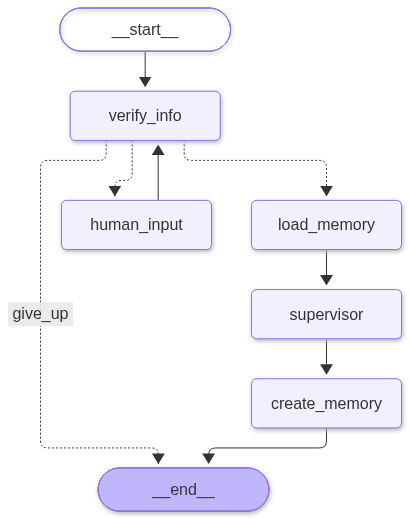

In [11]:
# Build the graph once to draw it
from IPython.display import Image, display
from langgraph.checkpoint.memory import MemorySaver
from langgraph.store.memory import InMemoryStore

_graph = SupportGraphBuilder(get_llm(), chinook, InMemoryStore(), MemorySaver()).build()
try:
    display(Image(_graph.get_graph().draw_mermaid_png()))
except Exception:
    print(_graph.get_graph().draw_mermaid())  # fallback if the PNG renderer is unavailable

## 10. Testing
### Test case 1: phone + invoice + albums, then preferences (same thread and a new thread)

In [12]:
"""Entry point: build everything and run the two test cases."""
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import MemorySaver
from langgraph.store.memory import InMemoryStore
from langgraph.types import Command

class SupportApp:
    """Thin façade: builds the graph and offers a chat() method that handles interrupts."""

    def __init__(self):
        """Create llm, database, store and checkpointer, then compile the graph."""
        llm = get_llm()
        db = ChinookDatabase(Settings.CHINOOK_URL)
        self.store = InMemoryStore()
        self.checkpointer = MemorySaver()
        self.graph = SupportGraphBuilder(llm, db, self.store, self.checkpointer).build()

    def chat(self, question: str, thread_id: str, interactive: bool = True) -> str:
        """Send one user message and return the final reply.

        If the graph interrupts (it needs credentials), the prompt is printed. With
        interactive=True the answer is read from input(); with interactive=False the
        method returns the prompt so the caller can resume it with resume().
        """
        config = {"configurable": {"thread_id": thread_id}}
        result = self.graph.invoke({"messages": [HumanMessage(question)]}, config)
        return self._drive(result, config, interactive)

    def resume(self, answer: str, thread_id: str, interactive: bool = False) -> str:
        """Resume a paused thread with the human's answer."""
        config = {"configurable": {"thread_id": thread_id}}
        result = self.graph.invoke(Command(resume=answer), config)
        return self._drive(result, config, interactive)

    def _drive(self, result: dict, config: dict, interactive: bool) -> str:
        """Handle interrupts until the graph finishes (or hand the prompt back)."""
        while result.get("__interrupt__"):
            prompt = result["__interrupt__"][0].value
            if not interactive:
                return f"[INTERRUPT] {prompt}"
            print(f"Assistant: {prompt}")
            answer = input("You: ")
            result = self.graph.invoke(Command(resume=answer), config)
        return self._text(result["messages"][-1].content)

    @staticmethod
    def _text(content) -> str:
        """Message content may be a str or a list of content blocks; keep only the text."""
        if isinstance(content, str):
            return content
        return "".join(b.get("text", "") for b in content if isinstance(b, dict) and b.get("type") == "text")


def _show(label: str, text: str):
    print(f"\n--- {label} ---\n{text}")


def run_test_case_1(app: "SupportApp"):
    """Phone + invoice + albums, then a preference-based follow-up on the SAME thread."""
    thread = "test-case-1"
    q1 = ("My phone number is +55 (12) 3923-5555. How much was my most recent invoice, "
          "and can you recommend some Rolling Stones albums?")
    _show("Test 1, turn 1", app.chat(q1, thread, interactive=False))
    _show("Test 1, turn 2 (same thread)",
          app.chat("List some songs that match my preferences?", thread, interactive=False))

    # Long-term memory must survive a brand-new thread for the same customer.
    other = "test-case-1-new-thread"
    app.chat("My phone number is +55 (12) 3923-5555. Hi!", other, interactive=False)
    _show("Test 1, turn 3 (NEW thread, memory carried over)",
          app.chat("List some songs that match my preferences?", other, interactive=False))


app = SupportApp()
run_test_case_1(app)



C:\Users\Ahmed Reda\AppData\Local\Temp\ipykernel_39052\3038722009.py:43: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  return create_react_agent(
C:\Users\Ahmed Reda\AppData\Local\Temp\ipykernel_39052\3038722009.py:43: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  return create_react_agent(
Task supervisor with path ('__pregel_pull', 'supervisor') wrote to unknown channel remaining_steps, ignoring it.
Task supervisor with path ('__pregel_pull', 'supervisor') wrote to unknown channel remaining_steps, ignoring it.



--- Test 1, turn 1 ---
Your most recent invoice was **#382**, dated **August 7, 2025**, totaling **8.91**. The invoice data doesn’t specify the currency.

For Rolling Stones listening, our catalog has:
- **Hot Rocks, 1964–1971 (Disc 1)** — the recommended starting point.
- **No Security**
- **Voodoo Lounge**


Task supervisor with path ('__pregel_pull', 'supervisor') wrote to unknown channel remaining_steps, ignoring it.



--- Test 1, turn 2 (same thread) ---
Based on your interest in **The Rolling Stones**, try these songs from our catalog:

- “Paint It Black”
- “Satisfaction”
- “Under My Thumb”
- “Time Is On My Side”
- “Get Off Of My Cloud”
- “Play With Fire”

All are available on **Hot Rocks, 1964–1971 (Disc 1)**.

If you’d like something heavier, try AC/DC’s “For Those About To Rock (We Salute You)” or “Let’s Get It Up.”


Task supervisor with path ('__pregel_pull', 'supervisor') wrote to unknown channel remaining_steps, ignoring it.
Task supervisor with path ('__pregel_pull', 'supervisor') wrote to unknown channel remaining_steps, ignoring it.



--- Test 1, turn 3 (NEW thread, memory carried over) ---
Based on your taste for **The Rolling Stones**, try these songs from our catalog:

- “Paint It Black” — The Rolling Stones
- “Satisfaction” — The Rolling Stones
- “Time Is On My Side” — The Rolling Stones
- “Under My Thumb” — The Rolling Stones
- “Play With Fire” — The Rolling Stones
- “Get Off Of My Cloud” — The Rolling Stones

For something heavier:
- “For Those About To Rock (We Salute You)” — AC/DC
- “Restless and Wild” — Accept


### Test case 2: no credentials -> interrupt -> wrong phone -> valid email, plus the loop guard

In [13]:
def run_test_case_2(app: "SupportApp"):
    """NEW thread, no credentials -> interrupt; then wrong phone, then a valid one."""
    thread = "test-case-2"
    _show("Test 2, turn 1 (no credentials)",
          app.chat("What was my most recent invoice?", thread, interactive=False))
    _show("Test 2, wrong phone", app.resume("My phone is +1 (000) 000-0000", thread))
    _show("Test 2, valid email -> resumes", app.resume("my email is luisg@embraer.com.br", thread))

    # Loop guard: three bad answers must end the run instead of asking forever.
    guard = "test-case-2-guard"
    _show("Guard, attempt 1", app.chat("hello", guard, interactive=False))
    _show("Guard, attempt 2", app.resume("it's 123-456", guard))
    _show("Guard, attempt 3 (should give up)", app.resume("still nothing", guard))

run_test_case_2(app)


--- Test 2, turn 1 (no credentials) ---
[INTERRUPT] To help you, I first need to verify your account. Please provide your customer ID, email or phone number.

--- Test 2, wrong phone ---
[INTERRUPT] I couldn't find an account matching those details. Please check them and send your customer ID, email or phone number again.


Task supervisor with path ('__pregel_pull', 'supervisor') wrote to unknown channel remaining_steps, ignoring it.



--- Test 2, valid email -> resumes ---
Your most recent invoice is **#382**, dated **August 7, 2025**, for a total of **8.91**.

--- Guard, attempt 1 ---
[INTERRUPT] To help you, I first need to verify your account. Please provide your customer ID, email or phone number.

--- Guard, attempt 2 ---
[INTERRUPT] To help you, I first need to verify your account. Please provide your customer ID, email or phone number.

--- Guard, attempt 3 (should give up) ---
I couldn't verify your account after several attempts, so I can't continue. Please contact support or start a new conversation.


## Conclusion
**What worked:** the full flow from the spec runs: verification by ID, email or phone; routing to one or both sub-agents; pause and resume for missing credentials; and preferences that carry over to a new thread for the same customer.

**Limitations:** memory and checkpoints are in RAM and are lost on restart; the database is rebuilt from a download on every start; "similar artists" just means the same genre; preference extraction depends on the LLM; and verification trusts the credentials typed in chat, with no password.
